# Comparing the VAE and diffusion models

This notebook compares a convolutional VAE, an unconditional DDPM, and a class-conditional DDPM trained on MNIST and Fashion-MNIST. The comparison examines generated samples, validation noise-prediction losses for the diffusion models, sampling time, and class consistency. Existing checkpoints are used; the generative models are not retrained.

## 1. Setup

Experiment summaries and trained models are loaded from the project directories. Paths are resolved from either the repository root or the `notebooks` directory.

In [1]:
from pathlib import Path
import json
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import MNIST, FashionMNIST
from torchvision.transforms import ToTensor

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src").exists(), "Open the notebook from the project root or notebooks/."
sys.path.insert(0, str(ROOT))

from src.models import ConvVAE
from src.training import load_vae, set_seed
from src.diffusion_training import load_diffusion
from src.conditional_training import load_conditional

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 111
DATASETS = ["mnist", "fashion_mnist"]
CLASSES = {
    "mnist": [str(i) for i in range(10)],
    "fashion_mnist": ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
                      "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"],
}
FIG_DIR = ROOT / "results/figures/model_comparison"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Device:", device)

/home/stefano98/miniconda3/envs/vae-diffusion/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


## 2. Training results

The diffusion models are compared using their best validation noise-prediction MSE. The VAE optimizes a different objective (reconstruction loss and KL divergence), so its loss is not included in this numerical comparison.

In [2]:
def read_summary(path):
    if not path.exists():
        raise FileNotFoundError(f"Missing experiment summary: {path}")
    return json.loads(path.read_text())

rows = []
for dataset in DATASETS:
    for method, run_id in [
        ("Unconditional DDPM", f"{dataset}_baseline_v1_full"),
        ("Conditional DDPM", f"{dataset}_conditional_v1_full"),
    ]:
        folder = "diffusion" if method == "Unconditional DDPM" else "conditional_diffusion"
        summary = read_summary(ROOT / "results/metrics" / folder / run_id / "summary.json")
        rows.append({"dataset": dataset, "model": method, **summary})
results = pd.DataFrame(rows)
display(results[["dataset", "model", "best_epoch", "best_val_loss", "parameter_count"]].round(5))

,dataset,model,best_epoch,best_val_loss,parameter_count
0,mnist,Unconditional DDPM,30,0.03973,267361
1,mnist,Conditional DDPM,30,0.03953,268769
2,fashion_mnist,Unconditional DDPM,30,0.06933,267361
3,fashion_mnist,Conditional DDPM,28,0.07028,268769


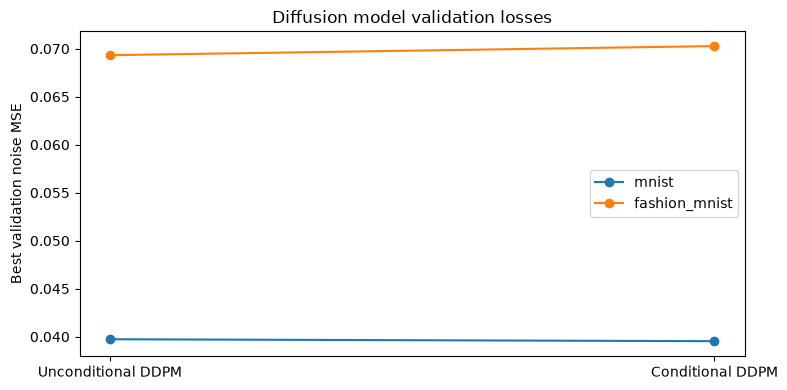

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for dataset in DATASETS:
    subset = results[results.dataset == dataset]
    ax.plot(subset.model, subset.best_val_loss, marker="o", label=dataset)
ax.set(ylabel="Best validation noise MSE", title="Diffusion model validation losses")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "diffusion_validation_comparison.png", dpi=160)
plt.show()

## 3. Load the trained models

The best checkpoints from the full experiments are used for generation. Model weights are stored locally rather than tracked in Git. The VAE with a 20-dimensional latent space is selected for this comparison; the 2D variant is examined in the VAE notebook.

In [4]:
def checkpoint_paths(dataset):
    return {
        "VAE (z=20)": ROOT / "checkpoints/vae" / f"baseline_v1_{dataset}_z20_full_seed111" / "best.pt",
        "Unconditional DDPM": ROOT / "results/checkpoints/diffusion" / f"{dataset}_baseline_v1_full" / "best.pt",
        "Conditional DDPM": ROOT / "results/checkpoints/conditional_diffusion" / f"{dataset}_conditional_v1_full" / "best.pt",
    }

for dataset in DATASETS:
    for method, path in checkpoint_paths(dataset).items():
        if not path.exists():
            raise FileNotFoundError(f"Missing {method} checkpoint: {path}")
print("All checkpoints found.")

All checkpoints found.


## 4. Compare generated samples

Eight images are generated for each model and dataset. The VAE and unconditional DDPM sample without class labels. The conditional DDPM is asked to generate classes 0–7, shown above its images. Because the other models are unconditional, columns do not represent matched classes across rows. The comparison is qualitative rather than a controlled image-by-image test.

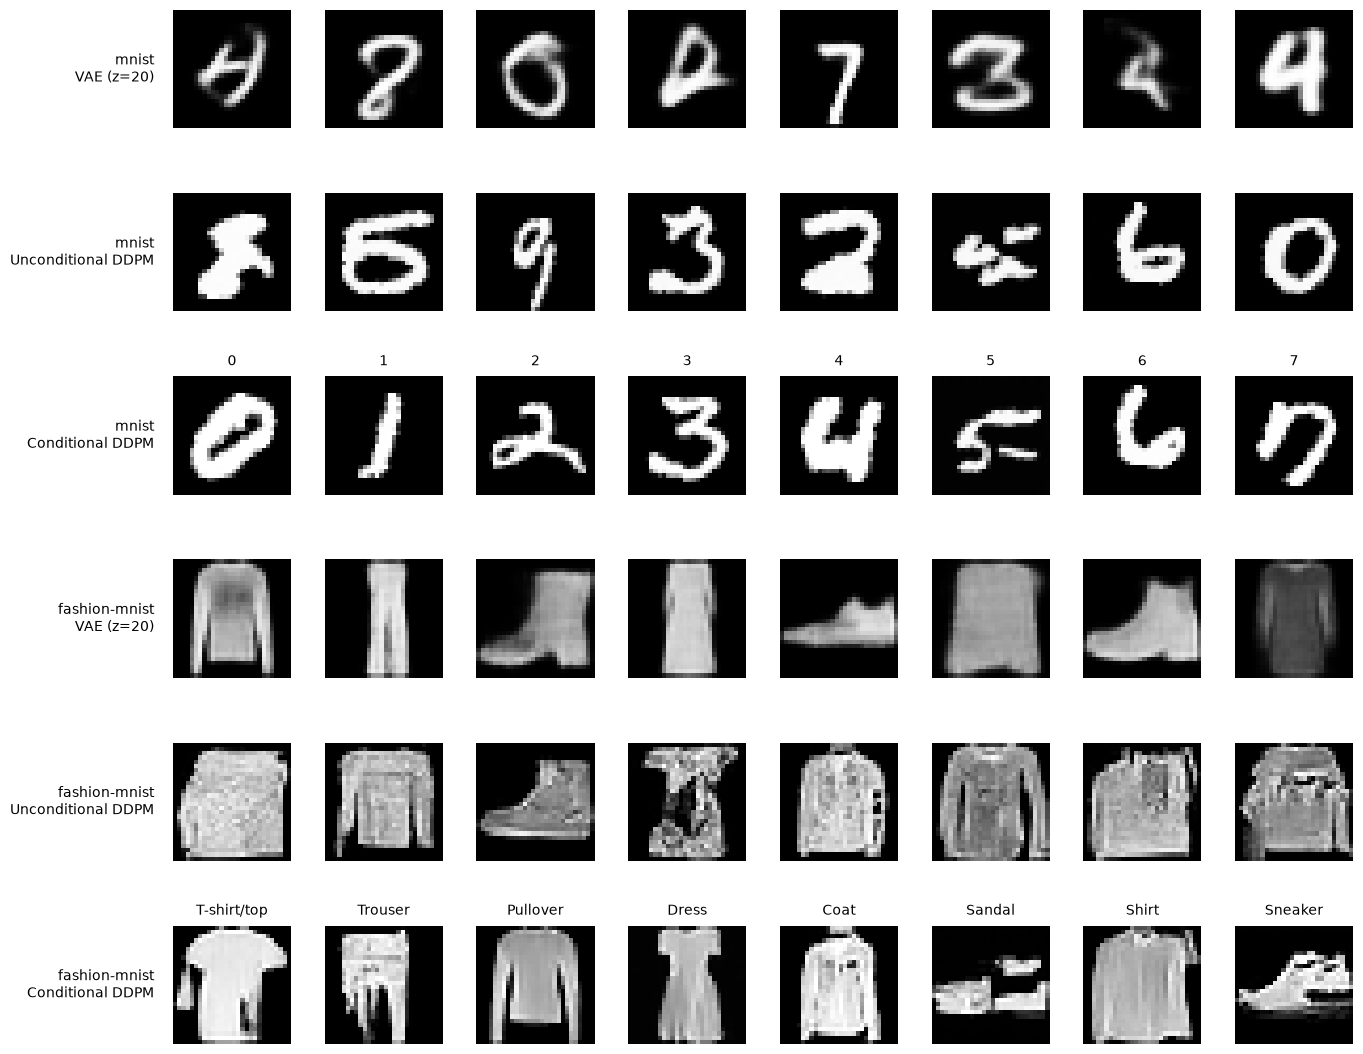

In [5]:
N_SAMPLES = 8
fig, axes = plt.subplots(6, N_SAMPLES, figsize=(15, 11))

for dataset_idx, dataset in enumerate(DATASETS):
    paths = checkpoint_paths(dataset)
    set_seed(SEED + 20)
    vae, _ = load_vae(paths["VAE (z=20)"], device)
    with torch.inference_mode():
        z = torch.randn(N_SAMPLES, 20, device=device)
        vae_images = vae.decode(z).cpu()
    del vae

    set_seed(SEED + 20)
    ddpm, process, _ = load_diffusion(paths["Unconditional DDPM"], device)
    with torch.inference_mode():
        ddpm_images = process.sample(ddpm, count=N_SAMPLES, device=device).cpu()
    del ddpm, process

    set_seed(SEED + 20)
    conditional, process, _ = load_conditional(paths["Conditional DDPM"], device)
    with torch.inference_mode():
        cond_images = process.sample(
            conditional, labels=list(range(N_SAMPLES)),
            device=device, guidance_scale=2.0
        ).cpu()
    del conditional, process

    for method_idx, (method, images) in enumerate([
        ("VAE (z=20)", vae_images),
        ("Unconditional DDPM", ddpm_images),
        ("Conditional DDPM", cond_images),
    ]):
        row = 3 * dataset_idx + method_idx
        for col, ax in enumerate(axes[row]):
            ax.imshow(images[col, 0], cmap="gray", vmin=0, vmax=1)
            ax.axis("off")
            if method_idx == 2:
                ax.set_title(CLASSES[dataset][col], fontsize=10, pad=8)

        # Use figure coordinates so labels remain visible with hidden image axes.
        axes[row, 0].text(
            -0.16, 0.5, f"{dataset.replace('_', '-')}\n{method}",
            transform=axes[row, 0].transAxes,
            ha="right", va="center", fontsize=10,
        )

fig.subplots_adjust(left=0.19, right=0.99, top=0.97, bottom=0.03,
                    wspace=0.10, hspace=0.55)
fig.savefig(FIG_DIR / "generated_samples_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Sampling time

Sampling time is measured for batches of eight images. The VAE requires one decoder pass, while diffusion uses multiple denoising steps. A warm-up run is performed before timing, and the median of three measurements is reported. Times depend on the hardware and batch size.

In [6]:
RUN_TIMING = True
TIMING_COUNT = 8

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()

if RUN_TIMING:
    timing_rows = []
    dataset = "mnist"
    paths = checkpoint_paths(dataset)
    for method in ["VAE (z=20)", "Unconditional DDPM", "Conditional DDPM"]:
        if method.startswith("VAE"):
            model, _ = load_vae(paths[method], device)
            def generate():
                return model.decode(torch.randn(TIMING_COUNT, 20, device=device))
        elif method == "Unconditional DDPM":
            model, process, _ = load_diffusion(paths[method], device)
            def generate():
                return process.sample(model, count=TIMING_COUNT, device=device)
        else:
            model, process, _ = load_conditional(paths[method], device)
            def generate():
                return process.sample(model, labels=[7] * TIMING_COUNT, device=device, guidance_scale=2.0)
        with torch.inference_mode():
            generate()
            synchronize()
            times = []
            for _ in range(3):
                start = time.perf_counter()
                generate()
                synchronize()
                times.append(time.perf_counter() - start)
        timing_rows.append({"model": method, "seconds_per_batch": np.median(times),
                            "seconds_per_image": np.median(times) / TIMING_COUNT})
        del model
        if not method.startswith("VAE"):
            del process
    timing = pd.DataFrame(timing_rows)
    display(timing.round(4))
    timing.to_csv(ROOT / "results/metrics/model_comparison_sampling_time.csv", index=False)

,model,seconds_per_batch,seconds_per_image
0,VAE (z=20),0.0004,0.0000
1,Unconditional DDPM,0.6950,0.0869
2,Conditional DDPM,1.1163,0.1395


## 6. Class consistency (optional)

A small classifier provides an approximate measure of whether generated images resemble the requested classes. The classifier is trained only on real training images and evaluated on the held-out test set before assessing generated samples. Its test accuracy should be reported alongside class agreement, since classifier predictions are not a direct measure of image quality.

In [9]:
RUN_CLASS_EVAL = True
CLASSIFIER_EPOCHS = 3
SAMPLES_PER_CLASS = 20  # 200 generated images per dataset
CLASS_BATCH_SIZE = 128

class SmallClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.features(x)

def train_classifier(dataset):
    cls = MNIST if dataset == "mnist" else FashionMNIST
    train_data = cls(ROOT / "data/raw", train=True, download=False, transform=ToTensor())
    test_data = cls(ROOT / "data/raw", train=False, download=False, transform=ToTensor())
    split_path = ROOT / "data/splits" / f"{dataset}_seed{SEED}.npz"
    with np.load(split_path) as split:
        indices = split["train_idx"].tolist()
    train_loader = DataLoader(Subset(train_data, indices), batch_size=CLASS_BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_data, batch_size=CLASS_BATCH_SIZE)
    classifier = SmallClassifier().to(device)
    optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)
    for epoch in range(CLASSIFIER_EPOCHS):
        classifier.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(classifier(x), y)
            loss.backward()
            optimizer.step()
        print(f"{dataset}: classifier epoch {epoch + 1}/{CLASSIFIER_EPOCHS}")
    classifier.eval()
    correct = total = 0
    with torch.inference_mode():
        for x, y in test_loader:
            predictions = classifier(x.to(device)).argmax(1).cpu()
            correct += (predictions == y).sum().item()
            total += len(y)
    accuracy = correct / total
    print(f"{dataset}: classifier test accuracy = {accuracy:.3f}")
    return classifier, accuracy

In [10]:
if RUN_CLASS_EVAL:
    set_seed(SEED)
    consistency_rows = []
    for dataset in DATASETS:
        classifier, test_accuracy = train_classifier(dataset)
        model, process, _ = load_conditional(checkpoint_paths(dataset)["Conditional DDPM"], device)
        for label in range(10):
            predictions = []
            for start in range(0, SAMPLES_PER_CLASS, 10):
                count = min(10, SAMPLES_PER_CLASS - start)
                with torch.inference_mode():
                    images = process.sample(model, labels=[label] * count,
                                            device=device, guidance_scale=2.0)
                    predictions.extend(classifier(images).argmax(1).cpu().tolist())
            consistency_rows.append({"dataset": dataset, "requested_class": label,
                                     "class_name": CLASSES[dataset][label],
                                     "agreement": np.mean(np.array(predictions) == label),
                                     "classifier_test_accuracy": test_accuracy,
                                     "n_samples": SAMPLES_PER_CLASS})
        del classifier, model, process
    consistency = pd.DataFrame(consistency_rows)
    display(consistency)
    consistency.to_csv(ROOT / "results/metrics/model_comparison_class_consistency.csv", index=False)
    display(consistency.groupby("dataset")["agreement"].mean().rename("mean_agreement"))

mnist: classifier epoch 1/3
mnist: classifier epoch 2/3
mnist: classifier epoch 3/3
mnist: classifier test accuracy = 0.986
fashion_mnist: classifier epoch 1/3
fashion_mnist: classifier epoch 2/3
fashion_mnist: classifier epoch 3/3
fashion_mnist: classifier test accuracy = 0.875


,dataset,requested_class,class_name,agreement,classifier_test_accuracy,n_samples
0,mnist,0,0,1.00,0.9859,20
1,mnist,1,1,1.00,0.9859,20
2,mnist,2,2,0.95,0.9859,20
3,mnist,3,3,1.00,0.9859,20
4,mnist,4,4,1.00,0.9859,20
5,mnist,5,5,1.00,0.9859,20
6,mnist,6,6,0.95,0.9859,20
7,mnist,7,7,0.90,0.9859,20
8,mnist,8,8,1.00,0.9859,20
9,mnist,9,9,1.00,0.9859,20


dataset
fashion_mnist    0.90
mnist            0.98
Name: mean_agreement, dtype: float64

### Class agreement by category

The average agreement provides an overall measure of class conditioning,
but it does not show how performance varies between categories.

The following figure presents the percentage of generated images classified
as the requested class. Each category is evaluated using 20 generated
samples.

The results are based on predictions from a classifier trained on real
images. Consequently, the agreement scores should not be interpreted
as exact measures of generation accuracy.

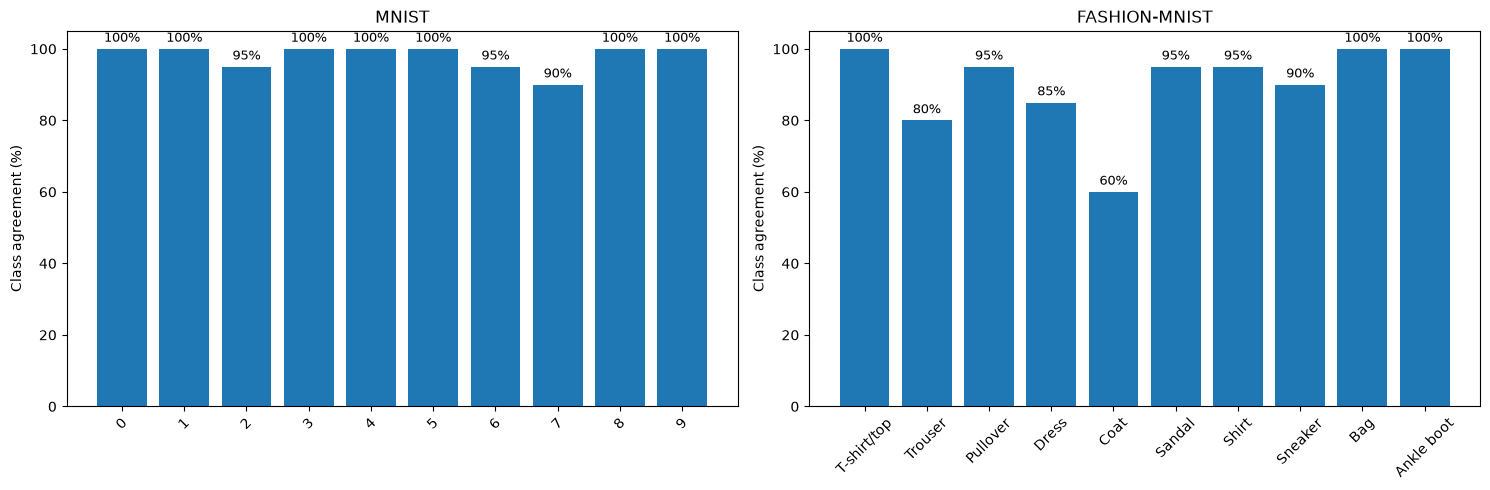

In [11]:
# Class agreement for each requested category
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, dataset in zip(axes, DATASETS):
    subset = consistency[consistency["dataset"] == dataset]

    ax.bar(
        subset["class_name"],
        subset["agreement"] * 100
    )

    ax.set_title(dataset.replace("_", "-").upper())
    ax.set_ylabel("Class agreement (%)")
    ax.set_ylim(0, 105)

    ax.tick_params(axis="x", rotation=45)

    for i, value in enumerate(subset["agreement"]):
        ax.text(
            i, value * 100 + 2,
            f"{value * 100:.0f}%",
            ha="center",
            fontsize=9
        )

plt.tight_layout()

fig.savefig(
    FIG_DIR / "class_consistency.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

## 7. Results and discussion

The three models produced recognizable images from MNIST and Fashion-MNIST, although differences in their outputs were observed. The VAE generated smoother images and was considerably faster, while the diffusion models generally produced more defined structures at a higher computational cost. Class conditioning provided additional control over generation, achieving classifier agreement rates of 98% for MNIST and 90% for Fashion-MNIST. Some clothing categories were more challenging, particularly Coat, which reached 60% agreement.

Overall, the experiments highlight the trade-off between sampling speed, image quality, and control over generation. However, visual inspection and classifier agreement do not fully measure the quality or diversity of generated images. Further evaluation using metrics such as FID and experiments with larger architectures could provide a more complete comparison.